#### Import Dependencies

In [65]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

#### Read in dataset

In [66]:
# set directory path
data_dir = Path("data/electric_school_bus_adoption_dataset_v10_2026-06jun")
data_file = data_dir / "ESB_adoption_dataset_v10_update_june_2026.xlsx"

# read in files
df = pd.read_excel(data_file)


#### Inspect all sheets and create dataframes

In [67]:
# excel sheet dictionary to name dataframes
sheet_map = {
    "1. District-level data": "districts",
    "2. Bus-level data": "buses",
    "3. State-level data": "states",
    "4. Utilities": "utilities",
    "5. Counties": "counties",
    "6. Congressional districts": "congress",
}

# read sheets
all_sheets = pd.read_excel(data_file, sheet_name=None)

# loop through sheets and create df
for sheet_name, name in sheet_map.items():
    globals()[f"df_{name}"] = all_sheets[sheet_name]
    print(f"Created df_{name} with shape {globals()[f'df_{name}'].shape}")

Created df_districts with shape (19520, 92)
Created df_buses with shape (14155, 40)
Created df_states with shape (57, 20)
Created df_utilities with shape (19186, 41)
Created df_counties with shape (25407, 6)
Created df_congress with shape (22695, 7)


#### Create master bus dataframe merging on LEA ID (local education agency ID)

In [68]:
df_master_buses = (
    df_buses.merge(
        df_districts, on="1c. LEA ID", how="left", suffixes=("", "_district")
    )
    .merge(df_utilities, on="1c. LEA ID", how="left", suffixes=("", "_utility"))
    .merge(df_states, on="1a. State", how="left", suffixes=("", "_state"))
)
print(
    f"Master Bus Table: {df_master_buses.shape[0]} buses, {df_master_buses.shape[1]} columns"
)
df_master_buses.head()

Master Bus Table: 14155 buses, 190 columns


,1a. State,1b. LEA or entity name,1c. LEA ID,1f. City,2c. Fleet operator 1,2c. Fleet operator 2,3a. Number of ESBs committed,3n. Current status of bus,3o. Batch,3p. Quarter awarded,...,3j. Average purchase price of Type C ESB (2022-2025),3k. Number of type c ESBs with purchase price data,3l. Minimum purchase price of a Type C ESB (2022-2025),3m. Maximum purchase price of a Type C ESB (2022-2025),8a. Approximate total number of students riding ESBs,"8b. Number of persons, mode to school: school bus","8c. Percent of persons, mode to school: school bus",8d. Pupil transportation requirement?,8e. Details,8f. Pupil transportation funding method
0,CALIFORNIA,Menlo School,80916,Atherton,Zum,NaN,1,Operating,1.0,2020 Q1,...,431297.256400,25.0,270647.74,472899.39,57819.82234,546000.0,0.089,No,NaN,Block grant
1,CALIFORNIA,The Nueva Middle School,89169,Hillsborough,Zum,NaN,1,Operating,1.0,2020 Q1,...,431297.256400,25.0,270647.74,472899.39,57819.82234,546000.0,0.089,No,NaN,Block grant
2,ALABAMA,Albertville City,100005,Albertville,NaN,NaN,19,Operating,1.0,2022 Q4,...,373142.155862,29.0,369610.23,375000.00,1090.20643,249000.0,0.363,NaN,NaN,NaN
3,ALABAMA,Albertville City,100005,Albertville,NaN,NaN,19,Operating,1.0,2022 Q4,...,373142.155862,29.0,369610.23,375000.00,1090.20643,249000.0,0.363,NaN,NaN,NaN
4,ALABAMA,Albertville City,100005,Albertville,NaN,NaN,19,Operating,1.0,2022 Q4,...,373142.155862,29.0,369610.23,375000.00,1090.20643,249000.0,0.363,NaN,NaN,NaN


#### Create district-level master dataframe

In [69]:
df_master_districts = df_districts.merge(
    df_utilities, on="1c. LEA ID", how="left", suffixes=("", "_utility")
).merge(df_states, on="1a. State", how="left", suffixes=("", "_state"))
print(
    f"Master District Table: {df_master_districts.shape[0]} districts, {df_master_districts.shape[1]} columns"
)
df_master_districts.head()

Master District Table: 19520 districts, 151 columns


,0a. Has Committed ESBs?,1a. State,1b. Local Education Agency (LEA) or entity name,1c. LEA ID,1d. Street address 1,1e. Street address 2,1f. City,1g. State,1h. ZIP code,1i. Website,...,3j. Average purchase price of Type C ESB (2022-2025),3k. Number of type c ESBs with purchase price data,3l. Minimum purchase price of a Type C ESB (2022-2025),3m. Maximum purchase price of a Type C ESB (2022-2025),8a. Approximate total number of students riding ESBs,"8b. Number of persons, mode to school: school bus","8c. Percent of persons, mode to school: school bus",8d. Pupil transportation requirement?,8e. Details,8f. Pupil transportation funding method
0,yes,ILLINOIS,Cook-Illinois Corp,17COOKI,NaN,NaN,NaN,IL,NaN,cookillinois.com,...,366359.790549,91.0,327287.32,400385.0,7516.265349,754000.0,0.371,Yes,"All districts except old type-unit, community ...",Partial Reimbursement of Allowable Costs
1,yes,MISSISSIPPI,ABERDEEN SCHOOL DIST,2800360,1100 W Commerce,NaN,Aberdeen,MS,39730.0,http://www.asdms.us,...,375148.296296,54.0,375000.00,375728.0,5298.138680,240000.0,0.502,NaN,NaN,NaN
2,no,ALABAMA,Alabama Youth Services,100002,1000 Industrial School Road,NaN,Mt Meigs,AL,36057.0,http://www.dys.alabama.gov/school-district.html,...,373142.155862,29.0,369610.23,375000.0,1090.206430,249000.0,0.363,NaN,NaN,NaN
3,yes,NEVADA,CLARK COUNTY SCHOOL DISTRICT,3200060,5100 WEST SAHARA AVE.,NaN,LAS VEGAS,NV,89146.0,NaN,...,NaN,NaN,NaN,NaN,1980.622222,159000.0,0.429,No,NaN,Block Grant
4,no,GEORGIA,Gwinnett County,1302550,52 Gwinnett Dr,NaN,Lawrenceville,GA,30045.0,NaN,...,375384.615385,117.0,375000.00,390000.0,6267.775039,847000.0,0.497,NaN,NaN,NaN


#### Print out column names from both master dataframes

In [70]:
df_master_buses.columns.tolist()

['1a. State',
 '1b. LEA or entity name',
 '1c. LEA ID',
 '1f. City',
 '2c. Fleet operator 1',
 '2c. Fleet operator 2',
 '3a. Number of ESBs committed ',
 '3n. Current status of bus',
 '3o. Batch',
 '3p. Quarter awarded',
 '3q. Quarter ordered',
 '3r. Quarter delivered',
 '3s. Quarter first operating',
 '3t. Bus OEM',
 '3u. Electric powertrain manufacturer',
 '3v. Model',
 '3w. Type',
 '3x. Dealer',
 '3y. Multiple funding sources used?',
 '3z. Funding source 1',
 '3aa. Agency administering funds 1',
 '3z. Funding source 2',
 '3aa. Agency administering funds 2',
 '3z. Funding source 3',
 '3aa. Agency administering funds 3',
 '3z. Funding source 4',
 '3aa. Agency administering funds 4',
 '3ab. Dollar amount toward bus',
 '3ac. Charging company',
 '3ad. Charging funding source',
 '3ae. Dollar amount toward charger',
 '3af. Notes 1',
 '3af. Notes 2',
 '7b. Source 1',
 '7b. Source 2',
 '7b. Source 3',
 '7b. Source 4',
 '7b. Source 5',
 '7b. Source 6',
 '7b. Source 7',
 '0a. Has Committed ESB

In [71]:
df_master_districts.columns.tolist()

['0a. Has Committed ESBs?',
 '1a. State',
 '1b. Local Education Agency (LEA) or entity name',
 '1c. LEA ID',
 '1d. Street address 1',
 '1e. Street address 2',
 '1f. City',
 '1g. State',
 '1h. ZIP code',
 '1i. Website',
 '1j. Has LEA ID?',
 '1k. LEA type (number)',
 '1l. LEA type (name)',
 '1m. Supervisory union LEA ID',
 '1n. Locale (full number)',
 '1o. Locale broad type (number)',
 '1p. Locale broad type (name)',
 '1q. Census Region',
 '1r. Census Division',
 '1s. Latitude',
 '1t. Longitude ',
 '2a. Total number of buses',
 '2b. Contractor used for some or all of buses?',
 '3a. Number of ESBs committed ',
 '3b. Number of delivered or operating ESBs',
 '3c. Number of ESBs awarded',
 '3d. Number of ESBs ordered',
 '3e. Number of ESBs delivered',
 '3f. Number of ESBs operating',
 '3g. Number of batches',
 '3h. Size of batch 1',
 '3h. Size of batch 2',
 '3h. Size of batch 3',
 '3h. Size of batch 4',
 '3h. Size of batch 5',
 '3i. Percent of fleet that is electric',
 '3j. Government agency

#### Explore Districts

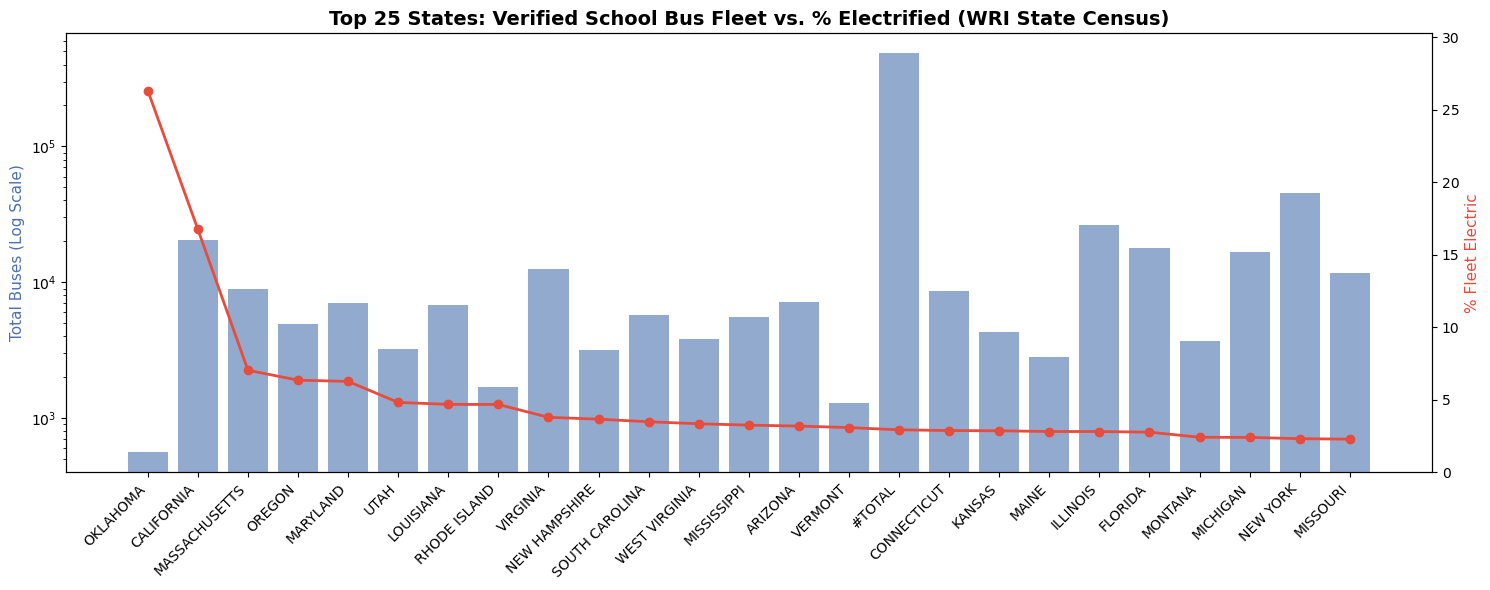

In [72]:
# remove any leading or lagging empty spaces
df_states.columns = df_states.columns.str.strip()

# Select State, SBF Fleet Census, and Committed ESBs
state_clean = df_states[
    [
        "1a. State",
        "2a. Total number of school buses (SBF 2022-23)",
        "3a. Number of committed ESBs",
    ]
].copy()

state_clean.columns = ["State", "Total_Buses", "Electric_Buses"]

# Convert to numeric & drop territories/US totals
state_clean["Total_Buses"] = pd.to_numeric(
    state_clean["Total_Buses"], errors="coerce"
)
state_clean["Electric_Buses"] = pd.to_numeric(
    state_clean["Electric_Buses"], errors="coerce"
)
state_clean = state_clean.dropna().query('State != "UNITED STATES"')

# Calculate true % electric
state_clean["pct_electric"] = (
    state_clean["Electric_Buses"] / state_clean["Total_Buses"]
) * 100
state_clean = state_clean.sort_values(by="pct_electric", ascending=False).head(
    25
)

# Plot
fig, ax1 = plt.subplots(figsize=(15, 6))

bars = ax1.bar(
    state_clean["State"],
    state_clean["Total_Buses"],
    color="#4c72b0",
    alpha=0.6,
    label="Total Buses",
)
ax1.set_yscale("log")
ax1.set_ylabel("Total Buses (Log Scale)", color="#4c72b0", fontsize=11)
ax1.set_xticks(range(len(state_clean)))
ax1.set_xticklabels(state_clean["State"], rotation=45, ha="right")

ax2 = ax1.twinx()
lines = ax2.plot(
    state_clean["State"],
    state_clean["pct_electric"],
    color="#e74c3c",
    marker="o",
    linewidth=2,
    label="% Electric",
)
ax2.set_ylabel("% Fleet Electric", color="#e74c3c", fontsize=11)
ax2.set_ylim(0, state_clean["pct_electric"].max() * 1.15)

plt.title(
    "Top 25 States: Verified School Bus Fleet vs. % Electrified (WRI State Census)",
    fontsize=14,
    fontweight="bold",
)
plt.tight_layout()
plt.show()


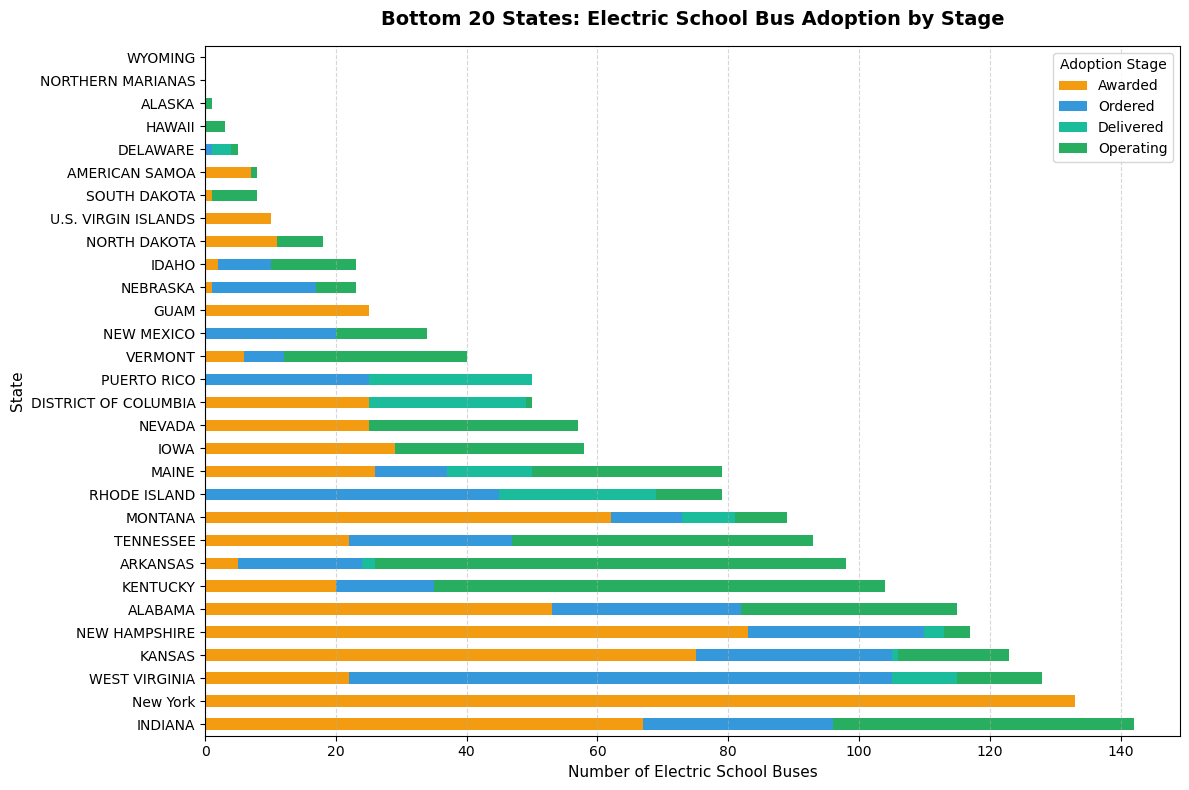

In [73]:

df_districts.columns = df_districts.columns.str.strip()

# aggregate the four WRI scenarios by state
stages_by_state = (
    df_districts.groupby("1a. State")
    .agg(
        Awarded=("3c. Number of ESBs awarded", "sum"),
        Ordered=("3d. Number of ESBs ordered", "sum"),
        Delivered=("3e. Number of ESBs delivered", "sum"),
        Operating=("3f. Number of ESBs operating", "sum"),
    )
    .reset_index()
)

# pick bottom twenty states and calculate "total" by summing the stages
stages_by_state["Total"] = stages_by_state[
    ["Awarded", "Ordered", "Delivered", "Operating"]
].sum(axis=1)
top_states = (
    stages_by_state.sort_values(by="Total", ascending=False)
    .tail(30)
    .set_index("1a. State")
)

# plot horizontal stacked bar chart
colors = [
    "#f39c12",
    "#3498db",
    "#1abc9c",
    "#27ae60",
]  # Amber (Awarded); Blue (Ordered); Teal (Delivered); Green (Operating)
ax = top_states[["Awarded", "Ordered", "Delivered", "Operating"]].plot(
    kind="barh", stacked=True, figsize=(12, 8), color=colors, edgecolor="none"
)

plt.title(
    "Bottom 20 States: Electric School Bus Adoption by Stage",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Number of Electric School Buses", fontsize=11)
plt.ylabel("State", fontsize=11)
plt.legend(title="Adoption Stage", frameon=True)
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


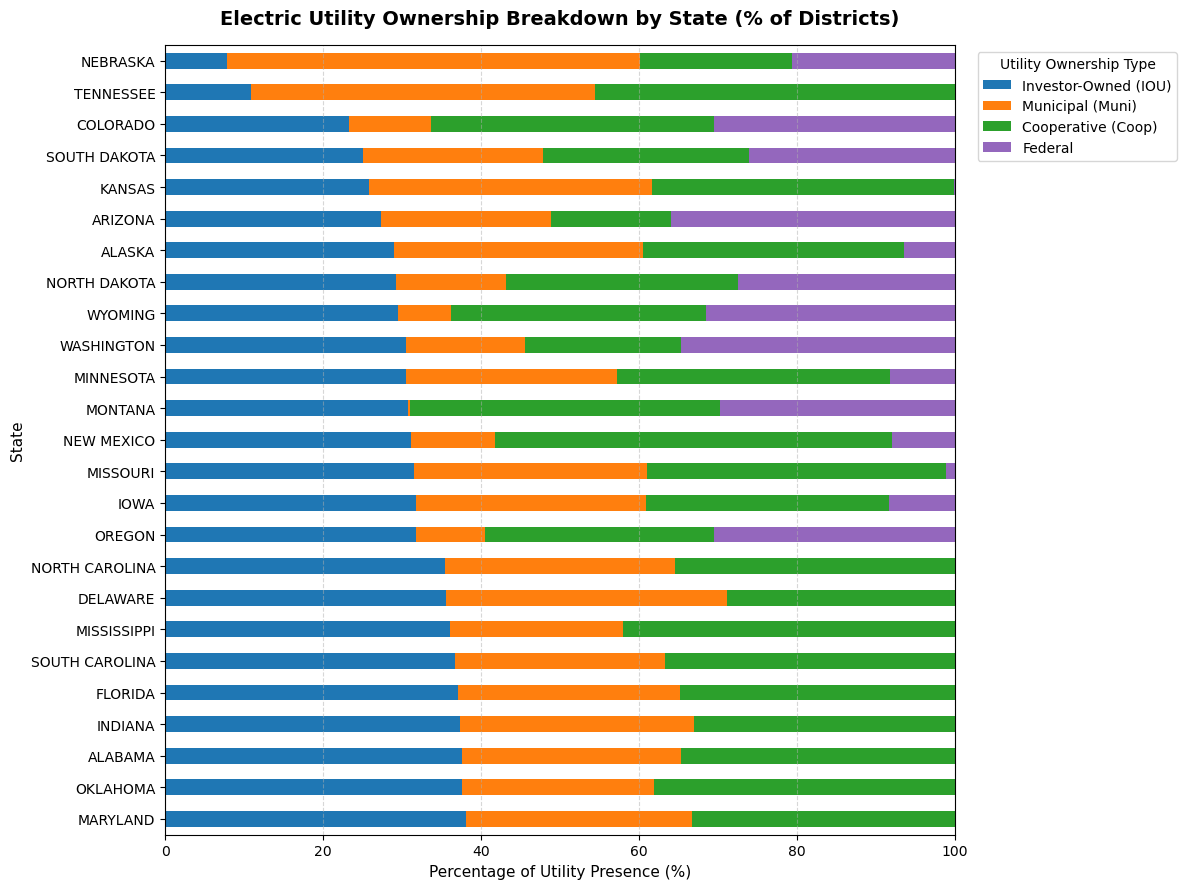

In [74]:
df_utilities.columns = df_utilities.columns.str.strip()

# dictionary to clean up labaels
ownership_cols = {
    "9d. Investor ownership": "Investor-Owned (IOU)",
    "9e. Municipal ownership": "Municipal (Muni)",
    "9b. Cooperative ownership": "Cooperative (Coop)",
    "9c. Federal ownership": "Federal",
}

# 3. Convert 'yes'/'no' to 1/0
util_subset = df_utilities[["1a. State"] + list(ownership_cols.keys())].copy()
for raw_col, clean_label in ownership_cols.items():
    util_subset[clean_label] = (
        util_subset[raw_col].astype(str).str.lower() == "yes"
    ).astype(int)

# sum by state
state_util = (
    util_subset.groupby("1a. State")[list(ownership_cols.values())]
    .sum()
    .reset_index()
)

# normalize to 100%
types = list(ownership_cols.values())
state_util["Total"] = state_util[types].sum(axis=1)
state_util = state_util[state_util["Total"] > 0].copy()

for t in types:
    state_util[t] = (state_util[t] / state_util["Total"]) * 100

# sort by investor-owned share
state_util = (
    state_util.sort_values(by="Investor-Owned (IOU)", ascending=False)
    .tail(25)
    .set_index("1a. State")
)

# stacked horizontal bar chart
colors = [
    "#1f77b4",  # Blue: Investor-Owned (IOU)
    "#ff7f0e",  # Orange: Municipal (Muni)
    "#2ca02c",  # Green: Cooperative (Coop)
    "#9467bd",  # Purple: Federal
]

ax = state_util[types].plot(
    kind="barh", stacked=True, figsize=(12, 9), color=colors, edgecolor="none"
)

plt.title(
    "Electric Utility Ownership Breakdown by State (% of Districts)",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Percentage of Utility Presence (%)", fontsize=11)
plt.ylabel("State", fontsize=11)
plt.xlim(0, 100)
plt.legend(title="Utility Ownership Type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


Bottom 20 States: ['WEST VIRGINIA', 'NEW YORK', 'ARIZONA', 'SOUTH CAROLINA', 'MONTANA', 'NEBRASKA', 'OREGON', 'MISSISSIPPI', 'MINNESOTA', 'UTAH', 'MARYLAND', 'ILLINOIS', 'DISTRICT OF COLUMBIA', 'VERMONT', 'COLORADO', 'PENNSYLVANIA', 'CALIFORNIA', 'MASSACHUSETTS', 'CONNECTICUT', 'RHODE ISLAND']


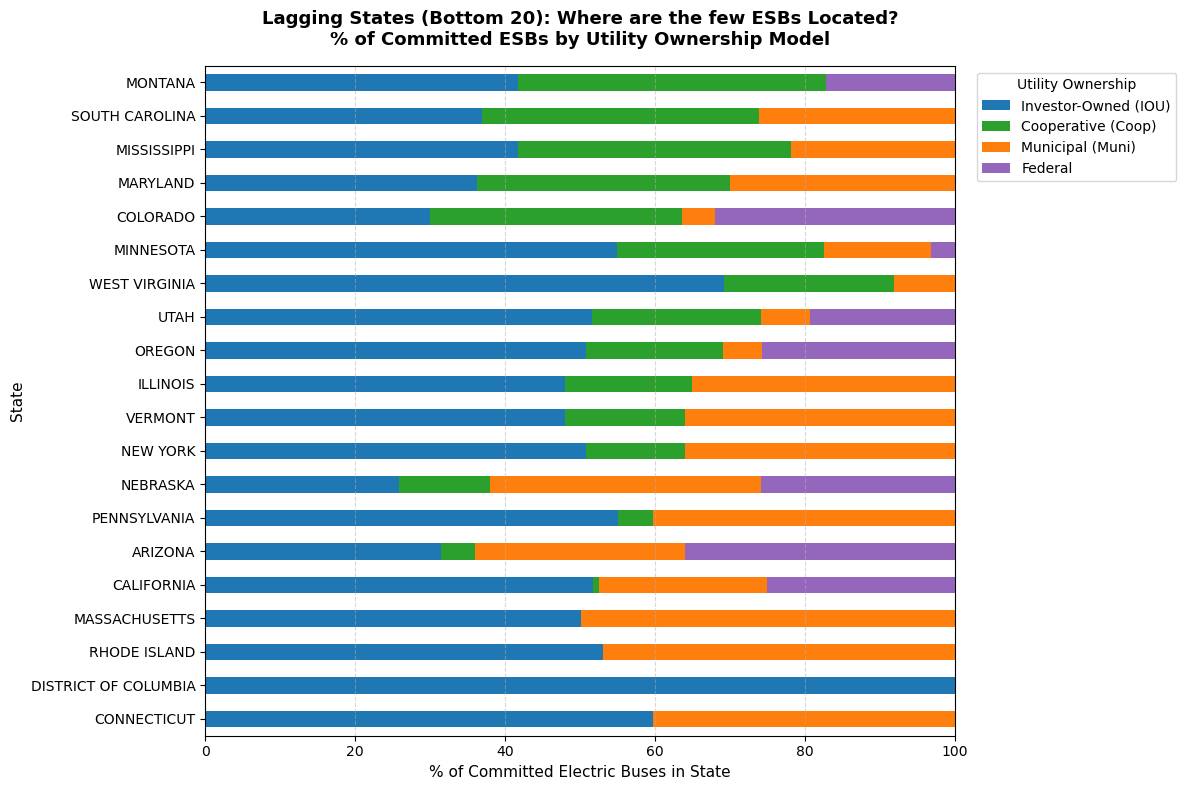

In [75]:
df_districts.columns = df_districts.columns.str.strip()
df_utilities.columns = df_utilities.columns.str.strip()

# 2. Identify the Bottom 20 States by adoption rate
state_rates = (
    df_districts.groupby("1a. State")
    .agg(
        total_buses=("2a. Total number of buses", "sum"),
        electric_buses=("3a. Number of ESBs committed", "sum"),
    )
    .reset_index()
)
state_rates["pct_electric"] = (
    state_rates["electric_buses"] / state_rates["total_buses"]
) * 100

# Exclude 0-total territories, sort ascending, and take the bottom 20
bottom_20_states = (
    state_rates[state_rates["total_buses"] > 0]
    .sort_values(by="pct_electric", ascending=True)
    .tail(20)["1a. State"]
    .tolist()
)

print("Bottom 20 States:", bottom_20_states)

# 3. Merge District ESB counts with Utility Ownership
dist_esb = df_districts[["1c. LEA ID", "1a. State", "3a. Number of ESBs committed"]].copy()
dist_esb = dist_esb[dist_esb["1a. State"].isin(bottom_20_states)]

util_types = {
    "9d. Investor ownership": "Investor-Owned (IOU)",
    "9b. Cooperative ownership": "Cooperative (Coop)",
    "9e. Municipal ownership": "Municipal (Muni)",
    "9c. Federal ownership": "Federal",
}

merged = dist_esb.merge(
    df_utilities[["1c. LEA ID"] + list(util_types.keys())],
    on="1c. LEA ID",
    how="inner",
)

# 4. Weight each utility type by the number of ESBs committed
for raw_col, label in util_types.items():
    is_served = (merged[raw_col].astype(str).str.lower() == "yes").astype(int)
    merged[label] = is_served * merged["3a. Number of ESBs committed"]

# 5. Aggregate ESBs by utility type across the bottom 20 states
type_labels = list(util_types.values())
state_esb_util = (
    merged.groupby("1a. State")[type_labels].sum()
)

# Keep states with at least 1 committed ESB and normalize to 100%
state_esb_util = state_esb_util[state_esb_util.sum(axis=1) > 0]
state_esb_pct = state_esb_util.div(state_esb_util.sum(axis=1), axis=0) * 100

# Sort by Cooperative share
state_esb_pct = state_esb_pct.sort_values(by="Cooperative (Coop)", ascending=True)

# 6. Plot 100% Stacked Bar Chart for the Lagging States
colors = [
    "#1f77b4",  # Blue: IOU
    "#2ca02c",  # Green: Coop
    "#ff7f0e",  # Orange: Muni
    "#9467bd",  # Purple: Federal
]

ax = state_esb_pct.plot(
    kind="barh",
    stacked=True,
    figsize=(12, 8),
    color=colors,
    edgecolor="none"
)

plt.title(
    "Lagging States (Bottom 20): Where are the few ESBs Located?\n"
    "% of Committed ESBs by Utility Ownership Model",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
plt.xlabel("% of Committed Electric Buses in State", fontsize=11)
plt.ylabel("State", fontsize=11)
plt.xlim(0, 100)
plt.legend(title="Utility Ownership", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


/var/folders/n5/zst858td3bv9wq29mv510yrc0000gn/T/ipykernel_29221/700478443.py:81: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


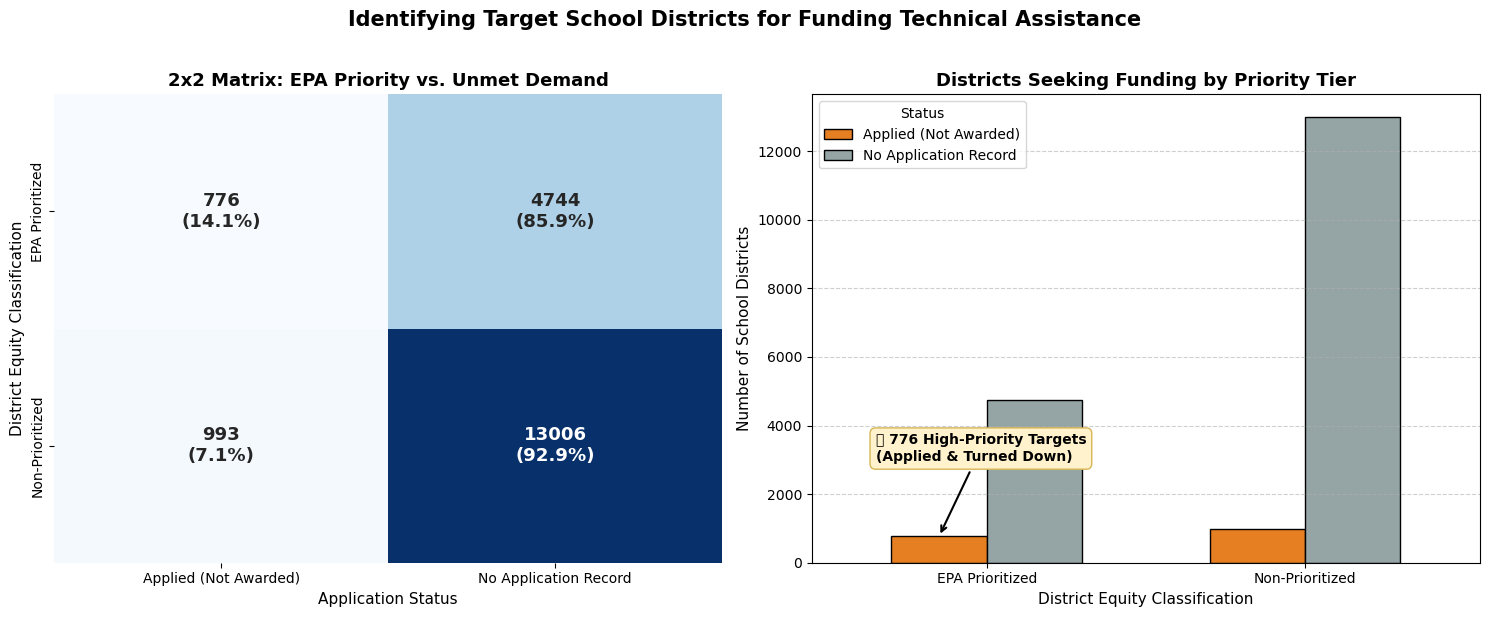

In [76]:
# 1. Clean column headers
df_districts.columns = df_districts.columns.str.strip()
prio_col = "5p. EPA 2023 Clean School Bus Grant & Rebate Programs prioritized school district?"
applied_not_awarded_col = "6e. Applied for ESB funding but not awarded"
# 2. Create clean categorical flags
df_matrix = df_districts[[prio_col, applied_not_awarded_col]].copy()
df_matrix["EPA_Prioritized"] = df_matrix[prio_col].map(
    {"Yes": "EPA Prioritized", "No": "Non-Prioritized"}
)
df_matrix["Application_Status"] = df_matrix[applied_not_awarded_col].apply(
    lambda x: (
        "Applied (Not Awarded)"
        if pd.notna(x) and str(x).strip() != ""
        else "No Application Record"
    )
)
# Drop any unclassified rows
df_matrix = df_matrix.dropna(subset=["EPA_Prioritized"])
# 3. Build 2x2 Crosstab
crosstab = pd.crosstab(
    df_matrix["EPA_Prioritized"], df_matrix["Application_Status"]
)
# Calculate percentages within each priority group
crosstab_pct = crosstab.div(crosstab.sum(axis=1), axis=0) * 100
# 4. Plot Side-by-Side: 2x2 Heatmap + Grouped Bar Chart
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
# Panel 1: 2x2 Matrix Heatmap with raw counts and percentages
labels = (
    crosstab.values.astype(str)
    + "\n("
    + crosstab_pct.round(1).values.astype(str)
    + "%)"
)
sns.heatmap(
    crosstab,
    annot=labels,
    fmt="",
    cmap="Blues",
    cbar=False,
    ax=ax1,
    annot_kws={"size": 13, "weight": "bold"},
)
ax1.set_title(
    "2x2 Matrix: EPA Priority vs. Unmet Demand", fontsize=13, fontweight="bold"
)
ax1.set_xlabel("Application Status", fontsize=11)
ax1.set_ylabel("District Equity Classification", fontsize=11)
# Panel 2: Grouped Bar Chart comparing the counts
crosstab[["Applied (Not Awarded)", "No Application Record"]].plot(
    kind="bar",
    ax=ax2,
    color=["#e67e22", "#95a5a6"],
    edgecolor="black",
    width=0.6,
)
ax2.set_title(
    "Districts Seeking Funding by Priority Tier", fontsize=13, fontweight="bold"
)
ax2.set_xlabel("District Equity Classification", fontsize=11)
ax2.set_ylabel("Number of School Districts", fontsize=11)
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=0)
ax2.grid(axis="y", linestyle="--", alpha=0.6)
ax2.legend(title="Status", frameon=True)
# Annotate the key insight bar (776 targets)
applied_prio_val = crosstab.loc["EPA Prioritized", "Applied (Not Awarded)"]
ax2.annotate(
    f"🎯 776 High-Priority Targets\n(Applied & Turned Down)",
    xy=(0 - 0.15, applied_prio_val),
    xytext=(-0.35, applied_prio_val + 2200),
    arrowprops=dict(facecolor="black", arrowstyle="->", lw=1.5),
    fontsize=10,
    fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="#fff2cc", edgecolor="#d6b656"),
)
plt.suptitle(
    "Identifying Target School Districts for Funding Technical Assistance",
    fontsize=15,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()


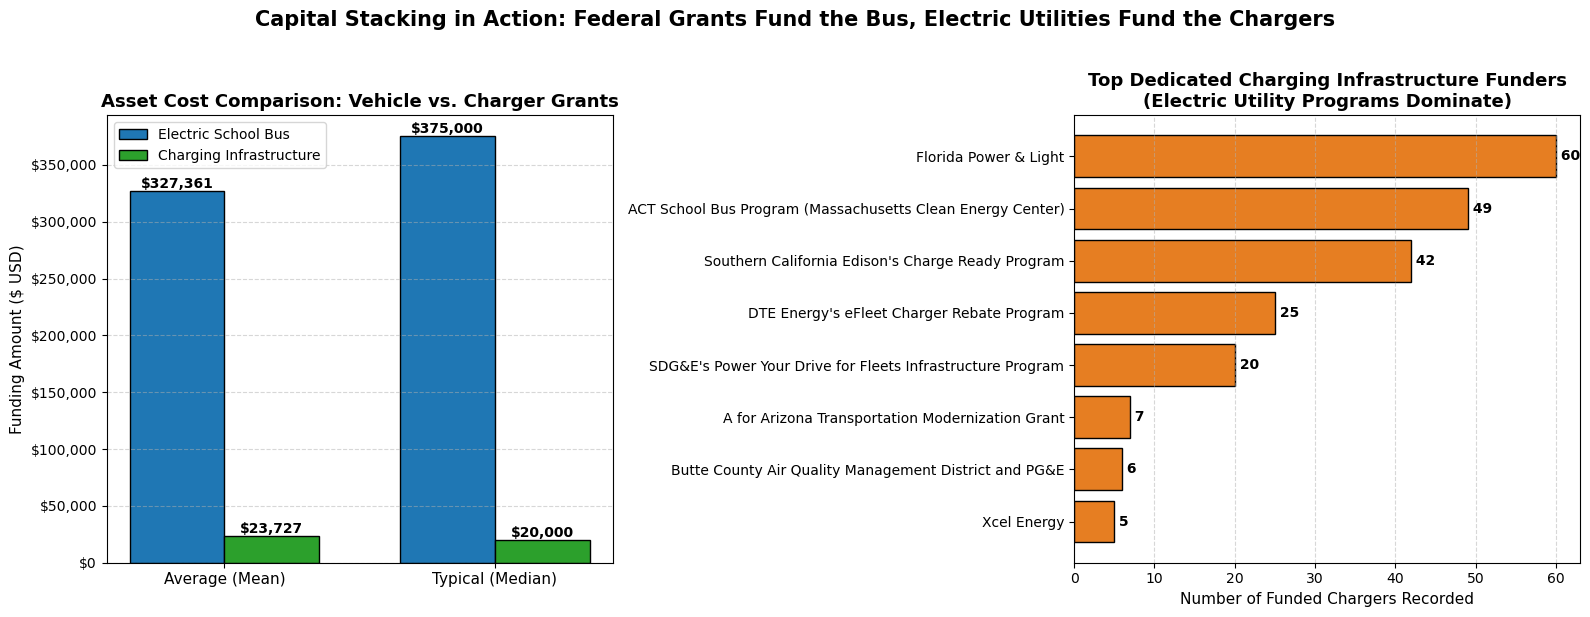

In [77]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Clean column headers
df_buses.columns = df_buses.columns.str.strip()

bus_amt_col = "3ab. Dollar amount toward bus"
charger_amt_col = "3ae. Dollar amount toward charger"
charger_funder_col = "3ad. Charging funding source"
bus_funder_col = "3z. Funding source 1"

# 2. Convert dollar columns to numeric
bus_dollars = pd.to_numeric(df_buses[bus_amt_col], errors="coerce").dropna()
charger_dollars = pd.to_numeric(
    df_buses[charger_amt_col], errors="coerce"
).dropna()

# 3. Get top dedicated charging infrastructure funders
charger_counts = (
    df_buses[charger_funder_col].dropna().astype(str).value_counts()
)

# Filter out placeholder numeric IDs (e.g. '12166') and take top 8
charger_funders = (
    charger_counts[~charger_counts.index.str.isnumeric()]
    .head(8)
    .sort_values(ascending=True)
)

# 4. Create Side-by-Side Figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# --- Panel 1: Average & Median Funding (Bus vs Charger) ---
metrics = ["Average (Mean)", "Typical (Median)"]
bus_vals = [bus_dollars.mean(), bus_dollars.median()]
charger_vals = [charger_dollars.mean(), charger_dollars.median()]

x = np.arange(len(metrics))
width = 0.35

rects1 = ax1.bar(
    x - width / 2,
    bus_vals,
    width,
    label="Electric School Bus",
    color="#1f77b4",
    edgecolor="black",
)
rects2 = ax1.bar(
    x + width / 2,
    charger_vals,
    width,
    label="Charging Infrastructure",
    color="#2ca02c",
    edgecolor="black",
)

ax1.set_ylabel("Funding Amount ($ USD)", fontsize=11)
ax1.set_title(
    "Asset Cost Comparison: Vehicle vs. Charger Grants",
    fontsize=13,
    fontweight="bold",
)
ax1.set_xticks(x)
ax1.set_xticklabels(metrics, fontsize=11)
ax1.yaxis.set_major_formatter("${x:,.0f}")
ax1.legend(frameon=True)
ax1.grid(axis="y", linestyle="--", alpha=0.5)

# Value labels on bars
for bar in rects1:
    h = bar.get_height()
    ax1.annotate(
        f"${h:,.0f}",
        (bar.get_x() + bar.get_width() / 2, h),
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )
for bar in rects2:
    h = bar.get_height()
    ax1.annotate(
        f"${h:,.0f}",
        (bar.get_x() + bar.get_width() / 2, h),
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

# --- Panel 2: Who Funds the Chargers? ---
bars = ax2.barh(
    charger_funders.index,
    charger_funders.values,
    color="#e67e22",
    edgecolor="black",
)
ax2.set_xlabel("Number of Funded Chargers Recorded", fontsize=11)
ax2.set_title(
    "Top Dedicated Charging Infrastructure Funders\n(Electric Utility Programs Dominate)",
    fontsize=13,
    fontweight="bold",
)
ax2.grid(axis="x", linestyle="--", alpha=0.5)

# Value labels on bars
for bar in bars:
    w = bar.get_width()
    ax2.annotate(
        f" {int(w)}",
        (w, bar.get_y() + bar.get_height() / 2),
        ha="left",
        va="center",
        fontsize=10,
        fontweight="bold",
    )

plt.suptitle(
    "Capital Stacking in Action: Federal Grants Fund the Bus, Electric Utilities Fund the Chargers",
    fontsize=15,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()


In [80]:

# 1. Clean headers
df_districts.columns = df_districts.columns.str.strip()
df_utilities.columns = df_utilities.columns.str.strip()

candidates = df_districts.copy()

fleet_col = "2a. Total number of buses"
esb_col = "3a. Number of ESBs committed"
lunch_col = "4e. Percentage of students in district eligible for free or reduced price lunch"
prio_col = "5p. EPA 2023 Clean School Bus Grant & Rebate Programs prioritized school district?"
denied_col = "6e. Applied for ESB funding but not awarded"
name_col = "1b. Local Education Agency (LEA) or entity name"
state_col = "1a. State"
locale_col = "1p. Locale broad type (name)"

# Convert numeric fields
candidates[fleet_col] = pd.to_numeric(
    candidates[fleet_col], errors="coerce"
).fillna(0)
candidates[esb_col] = pd.to_numeric(
    candidates[esb_col], errors="coerce"
).fillna(0)
candidates[lunch_col] = (
    pd.to_numeric(candidates[lunch_col], errors="coerce").fillna(0) * 100
)

# Apply 4 filter criteria
target_districts = candidates[
    (candidates[prio_col] == "Yes")
    & (candidates[denied_col].notna())
    & (candidates[denied_col].str.strip() != "")
    & (candidates[esb_col] == 0)
    & (candidates[fleet_col] >= 20)
].copy()

# Join primary utility from df_utilities
util_map = df_utilities[["1c. LEA ID", "9a. Utility name 1"]].dropna(
    subset=["1c. LEA ID"]
)
target_districts = target_districts.merge(util_map, on="1c. LEA ID", how="left")
target_districts["Primary Utility"] = target_districts[
    "9a. Utility name 1"
].fillna("Local Utility / Municipal")

target_districts = target_districts.sort_values(by=fleet_col, ascending=False)
print(f"Found {len(target_districts)} prime target districts nationwide!")

# Show Top 10 Table
top_candidates = target_districts[
    [
        name_col,
        state_col,
        fleet_col,
        locale_col,
        lunch_col,
        "Primary Utility",
        denied_col,
    ]
].head(10)
top_candidates.columns = [
    "District Name",
    "State",
    "Fleet Size",
    "Locale",
    "Free Lunch %",
    "Primary Utility",
    "Programs Denied",
]
top_candidates


Found 201 prime target districts nationwide!


,District Name,State,Fleet Size,Locale,Free Lunch %,Primary Utility,Programs Denied
0,Columbus City Schools District,OHIO,905.0,Urban,0.000000,OHIO POWER CO,2022 CSBP rebate
1,Mobile County,ALABAMA,765.0,Urban,69.449201,ALABAMA POWER CO,2022 CSBP rebate
2,POLK,FLORIDA,654.0,Suburban,54.407711,"DUKE ENERGY FLORIDA, LLC",2022 CSBP rebate
3,ALDINE ISD,TEXAS,582.0,Suburban,91.585378,ENTERGY TEXAS INC.,2022 CSBP rebate
4,EL PASO ISD,TEXAS,372.0,Urban,75.844976,"RIO GRANDE ELECTRIC COOP, INC",2022 CSBP rebate
5,SPRING ISD,TEXAS,345.0,Suburban,84.235211,ENTERGY TEXAS INC.,2022 CSBP rebate
6,Newport News City Public Schools,VIRGINIA,340.0,Urban,87.965022,VIRGINIA ELECTRIC & POWER CO,2022 CSBP rebate
7,Norfolk City Public Schools,VIRGINIA,321.0,Urban,95.495495,VIRGINIA ELECTRIC & POWER CO,2022 CSBP rebate; 2023 CSBP grant
8,LA JOYA ISD,TEXAS,305.0,Suburban,93.638123,AEP TEXAS CENTRAL COMPANY,2022 CSBP rebate
9,Cleveland Municipal,OHIO,290.0,Urban,0.000000,CLEVELAND ELECTRIC ILLUM CO,2022 CSBP rebate


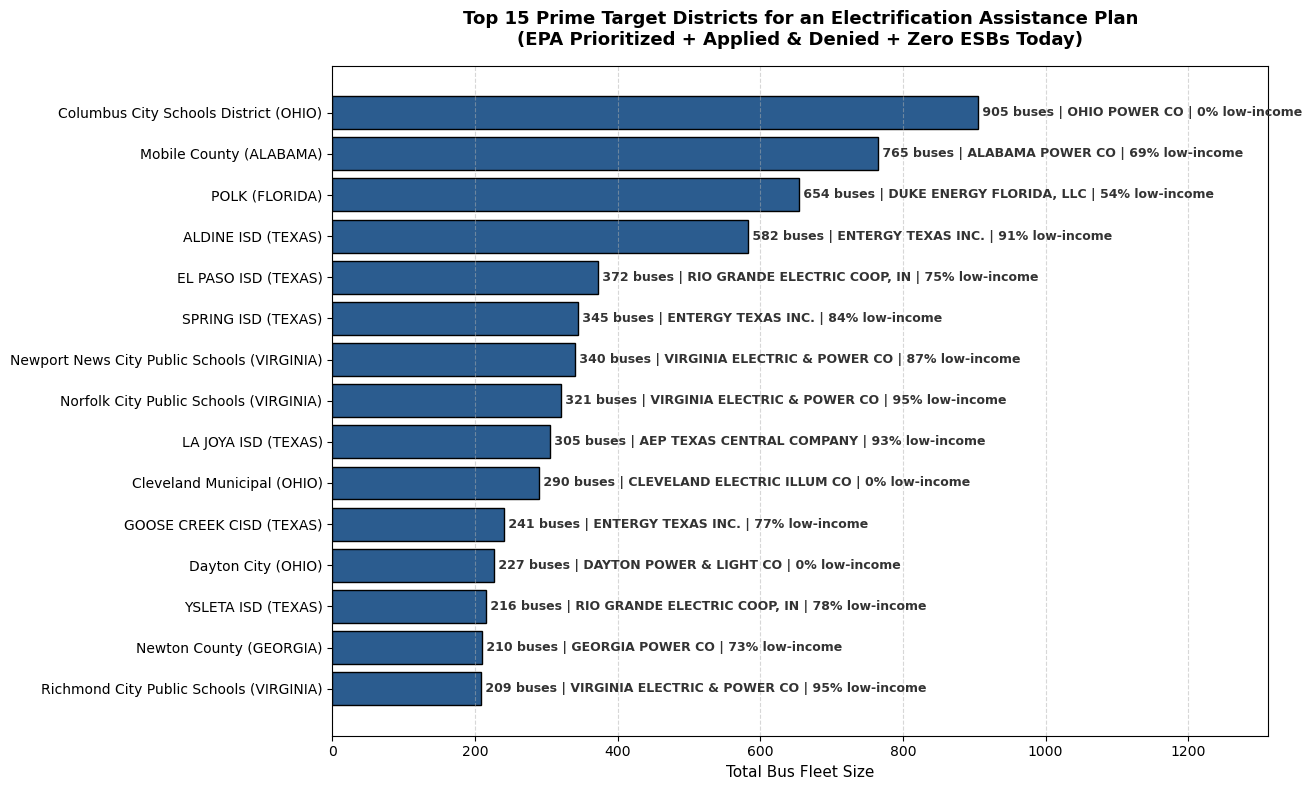

In [81]:


top_15 = target_districts.head(15).sort_values(
    by="2a. Total number of buses", ascending=True
)

fig, ax = plt.subplots(figsize=(13, 8))

bars = ax.barh(
    top_15["1b. Local Education Agency (LEA) or entity name"]
    + " ("
    + top_15["1a. State"]
    + ")",
    top_15["2a. Total number of buses"],
    color="#2b5c8f",
    edgecolor="black",
)

# Annotate each bar with utility and poverty rate
for bar, (_, row) in zip(bars, top_15.iterrows()):
    w = bar.get_width()
    util = str(row["Primary Utility"])[:28]
    lunch = int(
        row[
            "4e. Percentage of students in district eligible for free or reduced price lunch"
        ]
    )
    ax.annotate(
        f" {int(w)} buses | {util} | {lunch}% low-income",
        (w, bar.get_y() + bar.get_height() / 2),
        ha="left",
        va="center",
        fontsize=9,
        fontweight="bold",
        color="#333333",
    )

ax.set_xlabel("Total Bus Fleet Size", fontsize=11)
ax.set_title(
    "Top 15 Prime Target Districts for an Electrification Assistance Plan\n"
    "(EPA Prioritized + Applied & Denied + Zero ESBs Today)",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
ax.grid(axis="x", linestyle="--", alpha=0.5)
ax.set_xlim(0, top_15["2a. Total number of buses"].max() * 1.45)
plt.tight_layout()
plt.show()
